In [1]:
!pip -q install medmnist scikit-image scikit-learn opencv-python seaborn

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from medmnist import BloodMNIST
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

In [3]:
ROLL = "034"
SEED = int(ROLL[-2:])

HOG_CELL = (8, 8)
SIFT_GRID = 4

CLASSES = [1, 5, 6, 7]
NAMES = ["Eosinophil", "Monocyte", "Neutrophil", "Platelet"]

np.random.seed(SEED)
print("Seed:", SEED)

Seed: 34


In [4]:
train = BloodMNIST(split="train", size=64, download=True)
val = BloodMNIST(split="val", size=64, download=True)
test = BloodMNIST(split="test", size=64, download=True)

print("Train:", train.imgs.shape)
print("Validation:", val.imgs.shape)
print("Test:", test.imgs.shape)

100%|██████████| 156M/156M [01:34<00:00, 1.65MB/s]


Train: (11959, 64, 64, 3)
Validation: (1712, 64, 64, 3)
Test: (3421, 64, 64, 3)


In [5]:
def select_data(data, count):
    rng = np.random.default_rng(SEED)
    y = data.labels.ravel()
    ids = []

    for c in CLASSES:
        available = np.where(y == c)[0]
        ids.extend(rng.choice(available, count, replace=False))

    ids = np.array(ids)
    rng.shuffle(ids)
    return data.imgs[ids], y[ids]

X_train, y_train = select_data(train, 100)
X_val, y_val = select_data(val, 30)
X_test, y_test = select_data(test, 30)

In [6]:
for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(name, X.shape)
    print(dict(zip(NAMES, [sum(y == c) for c in CLASSES])))

Train (400, 64, 64, 3)
{'Eosinophil': np.int64(100), 'Monocyte': np.int64(100), 'Neutrophil': np.int64(100), 'Platelet': np.int64(100)}
Validation (120, 64, 64, 3)
{'Eosinophil': np.int64(30), 'Monocyte': np.int64(30), 'Neutrophil': np.int64(30), 'Platelet': np.int64(30)}
Test (120, 64, 64, 3)
{'Eosinophil': np.int64(30), 'Monocyte': np.int64(30), 'Neutrophil': np.int64(30), 'Platelet': np.int64(30)}


In [7]:
def preprocess(images):
    result = []
    for img in images:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        gray = cv2.resize(gray, (128, 128))
        result.append(gray)
    return np.array(result)

X_train = preprocess(X_train)
X_val = preprocess(X_val)
X_test = preprocess(X_test)

print(X_train.shape, X_val.shape, X_test.shape)

(400, 128, 128) (120, 128, 128) (120, 128, 128)


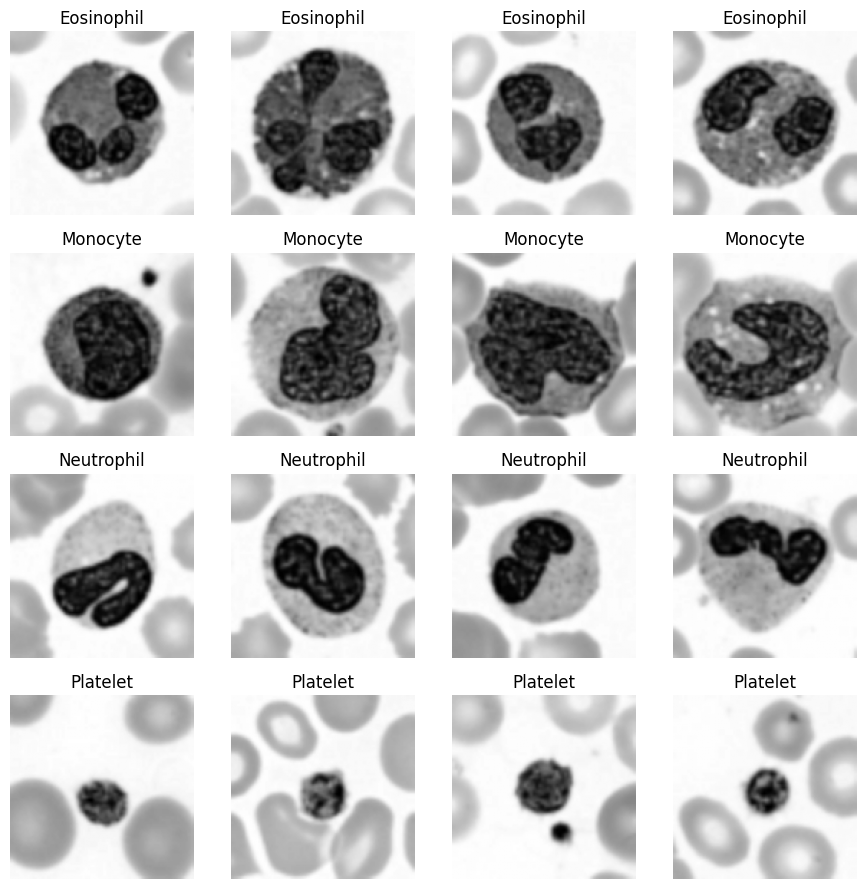

In [8]:
fig, ax = plt.subplots(4, 4, figsize=(9, 9))

for i, c in enumerate(CLASSES):
    ids = np.where(y_train == c)[0][:4]
    for j, idx in enumerate(ids):
        ax[i, j].imshow(X_train[idx], cmap="gray")
        ax[i, j].set_title(NAMES[i])
        ax[i, j].axis("off")

plt.tight_layout()
plt.show()

In [9]:
def hog_features(images):
    return np.array([
        hog(img, orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2))
        for img in images
    ])

H_train = hog_features(X_train)
H_val = hog_features(X_val)

print("HOG shape:", H_train.shape)
print("Feature length:", H_train.shape[1])

HOG shape: (400, 8100)
Feature length: 8100


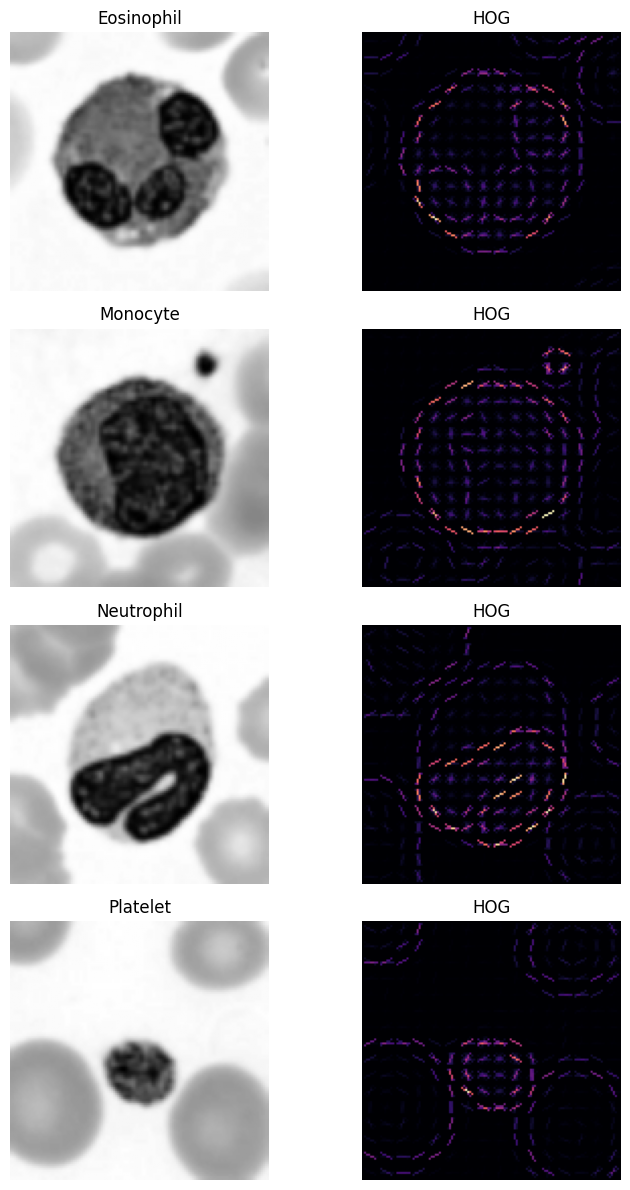

In [10]:
fig, ax = plt.subplots(4, 2, figsize=(8, 12))

for i, c in enumerate(CLASSES):
    img = X_train[np.where(y_train == c)[0][0]]
    features, visual = hog(
        img, orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=True
    )

    ax[i, 0].imshow(img, cmap="gray")
    ax[i, 1].imshow(visual, cmap="magma")
    ax[i, 0].set_title(NAMES[i])
    ax[i, 1].set_title("HOG")
    ax[i, 0].axis("off")
    ax[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [11]:
def train_svm(Xtr, Xv):
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(Xtr)
    Xv = scaler.transform(Xv)

    best_acc = -1
    best_model = None
    best_c = None

    for c in [0.1, 1, 10]:
        model = LinearSVC(C=c, max_iter=20000, random_state=SEED)
        model.fit(Xtr, y_train)
        pred = model.predict(Xv)
        acc = accuracy_score(y_val, pred)
        print("C:", c, "Accuracy:", round(acc, 4))

        if acc > best_acc:
            best_acc = acc
            best_model = model
            best_c = c

    print("Best C:", best_c)
    return best_model, scaler

hog_model, hog_scaler = train_svm(H_train, H_val)

C: 0.1 Accuracy: 0.7
C: 1 Accuracy: 0.7
C: 10 Accuracy: 0.7
Best C: 0.1


Accuracy: 0.7
Macro F1: 0.6971357899766704


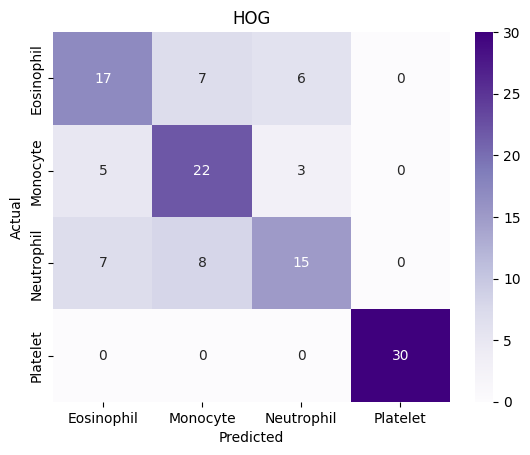

In [12]:
def evaluate(model, scaler, X, y, title):
    pred = model.predict(scaler.transform(X))
    print("Accuracy:", accuracy_score(y, pred))
    print("Macro F1:", f1_score(y, pred, average="macro"))

    cm = confusion_matrix(y, pred, labels=CLASSES)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
                xticklabels=NAMES, yticklabels=NAMES)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    return cm

hog_cm = evaluate(hog_model, hog_scaler, H_val, y_val, "HOG")

In [13]:
sift = cv2.SIFT_create()

counts = []
for img in X_train:
    kp, des = sift.detectAndCompute(img, None)
    counts.append(len(kp))

print("Average:", np.mean(counts))
print("Minimum:", np.min(counts))
print("Maximum:", np.max(counts))
print("Zero keypoints:", counts.count(0))

Average: 72.2975
Minimum: 9
Maximum: 178
Zero keypoints: 0


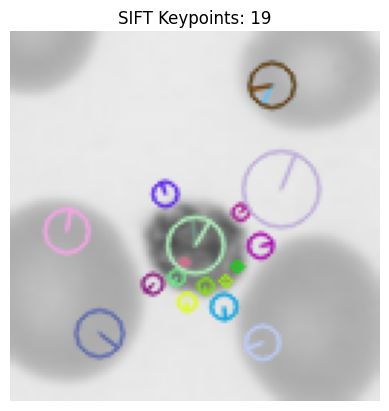

In [14]:
img = X_train[0]
kp, des = sift.detectAndCompute(img, None)

visual = cv2.drawKeypoints(img, kp, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.imshow(cv2.cvtColor(visual, cv2.COLOR_BGR2RGB))
plt.title(f"SIFT Keypoints: {len(kp)}")
plt.axis("off")
plt.show()

In [15]:
def sift_features(images):
    all_features = []

    for img in images:
        points = [
            cv2.KeyPoint(float(x), float(y), 32)
            for y in [16, 48, 80, 112]
            for x in [16, 48, 80, 112]
        ]

        kp, des = sift.compute(img, points)

        if des is None or len(des) != 16:
            raise ValueError("Expected 16 SIFT descriptors")

        all_features.append(des.flatten())

    return np.array(all_features)

S_train = sift_features(X_train)
S_val = sift_features(X_val)

print("SIFT shape:", S_train.shape)

SIFT shape: (400, 2048)


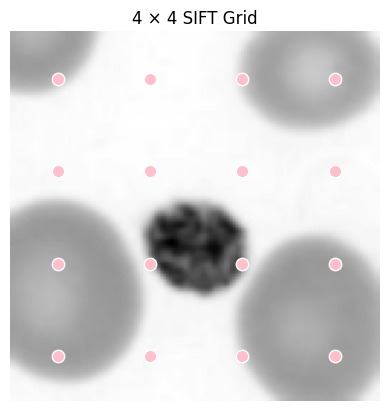

In [16]:
plt.imshow(X_train[0], cmap="gray")

for y in [16, 48, 80, 112]:
    for x in [16, 48, 80, 112]:
        plt.scatter(x, y, c="pink", s=80, edgecolors="white")

plt.title("4 × 4 SIFT Grid")
plt.axis("off")
plt.show()

In [17]:
sift_model, sift_scaler = train_svm(S_train, S_val)

C: 0.1 Accuracy: 0.7333
C: 1 Accuracy: 0.75
C: 10 Accuracy: 0.7417
Best C: 1


Accuracy: 0.75
Macro F1: 0.7492512195902026


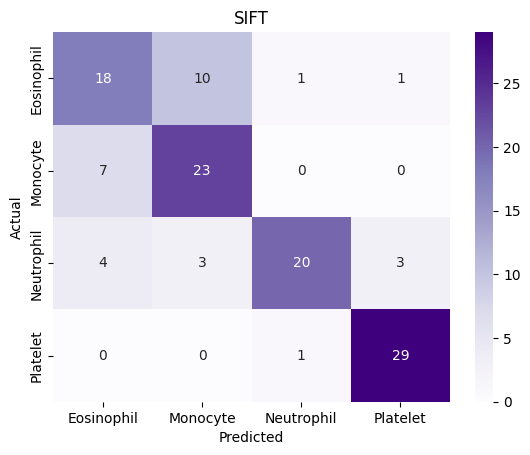

In [18]:
sift_cm = evaluate(
    sift_model, sift_scaler,
    S_val, y_val, "SIFT"
)

In [19]:
def rotate(img):
    M = cv2.getRotationMatrix2D((64, 64), 20, 1)
    return cv2.warpAffine(img, M, (128, 128))

X_rot = np.array([rotate(img) for img in X_test])

In [20]:
rng = np.random.default_rng(SEED)

def add_noise(img):
    noise = rng.normal(0, 0.05, img.shape)
    result = np.clip(img / 255.0 + noise, 0, 1)
    return (result * 255).astype(np.uint8)

X_noise = np.array([add_noise(img) for img in X_test])

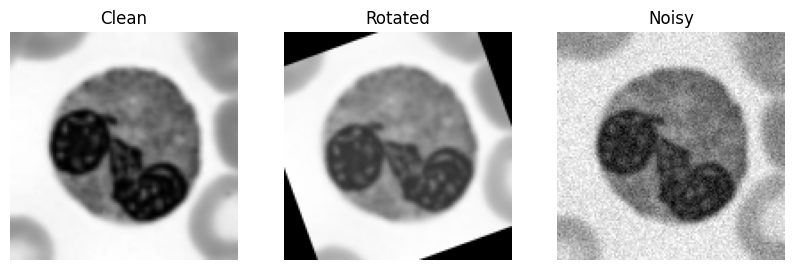

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(10, 4))

for a, img, title in zip(
    ax,
    [X_test[0], X_rot[0], X_noise[0]],
    ["Clean", "Rotated", "Noisy"]
):
    a.imshow(img, cmap="gray")
    a.set_title(title)
    a.axis("off")

plt.show()

In [22]:
results = []

for name, model, scaler, extractor in [
    ("HOG", hog_model, hog_scaler, hog_features),
    ("SIFT", sift_model, sift_scaler, sift_features)
]:
    scores = []
    for images in [X_test, X_rot, X_noise]:
        features = extractor(images)
        pred = model.predict(scaler.transform(features))
        scores.append(accuracy_score(y_test, pred))

    results.append([name] + scores)

df = pd.DataFrame(results,
    columns=["Model", "Clean", "Rotated", "Noisy"])

display(df)

,Model,Clean,Rotated,Noisy
0,HOG,0.775000,0.700000,0.250000
1,SIFT,0.741667,0.333333,0.691667


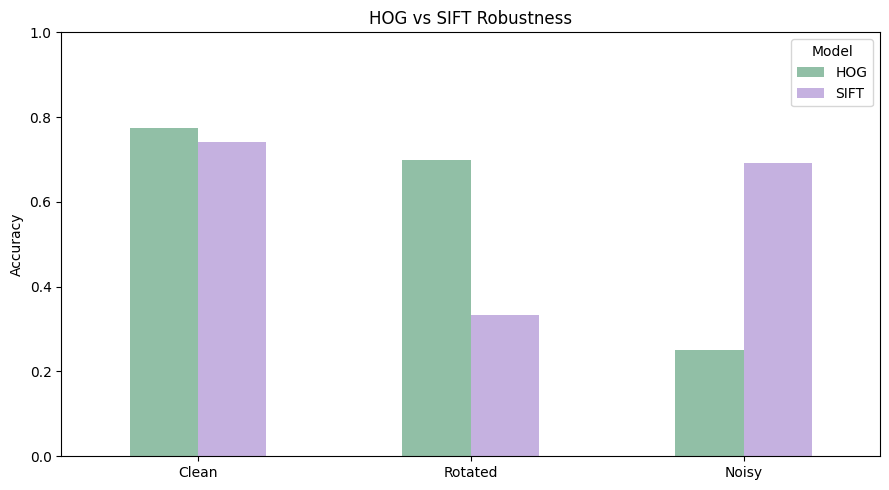

In [23]:
df.set_index("Model").T.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#91BFA6", "#C5B1E0"]
)

plt.title("HOG vs SIFT Robustness")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
cm = hog_cm + sift_cm
pairs = []

for i in range(4):
    for j in range(i + 1, 4):
        errors = cm[i, j] + cm[j, i]
        pairs.append((NAMES[i], NAMES[j], errors))

pairs.sort(key=lambda x: x[2], reverse=True)

print("Most confused classes:", pairs[0])

Most confused classes: ('Eosinophil', 'Monocyte', np.int64(29))
